In [1]:
!pip install pandas
!pip install matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.9/139.9 kB 2.0 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.2/383.2 kB 2.8 MB/s eta 0:00:00a 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 13.4 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 9.4 MB/s eta 0:00:00


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

runs = pd.DataFrame([
    {
        "variant": "Full",
        "width": 1672,
        "height": 941,
        "ttft_s": 110.93,
        "total_s": 111.60
    },
    {
        "variant": "Half",
        "width": 836,
        "height": 470,
        "ttft_s": 26.65,
        "total_s": 27.30
    }
])


print(runs)


  variant  width  height  ttft_s  total_s   pixels
0    Full   1672     941  110.93    111.6  1573352
1    Half    836     470   26.65     27.3   392920


In [3]:
r = runs.set_index("variant")
ttft_ratio   = r.loc["Full", "ttft_s"] / r.loc["Half", "ttft_s"]
print(ttft_ratio)

4.162476547842402


In [4]:

pixel_ratio = runs.iloc[0]["pixels"] / runs.iloc[1]["pixels"]
ttft_speedup = runs.iloc[0]["ttft_s"] / runs.iloc[1]["ttft_s"]

print(f"Pixel ratio: {pixel_ratio:.3f}x")
print(f"TTFT speedup: {ttft_speedup:.3f}x")


Pixel ratio: 4.004x
TTFT speedup: 4.162x


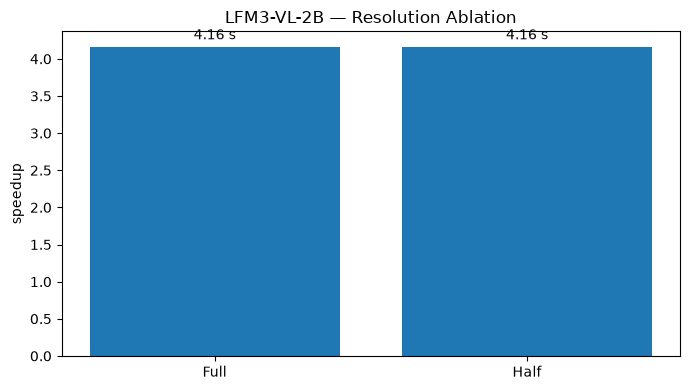

In [14]:

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(runs["variant"], ttft_speedup)

ax.set_ylabel("speedup")
ax.set_title("LFM3-VL-2B — Resolution Ablation")
ax.bar_label(bars, fmt="%.2f s", padding=3)

plt.tight_layout()
plt.show()


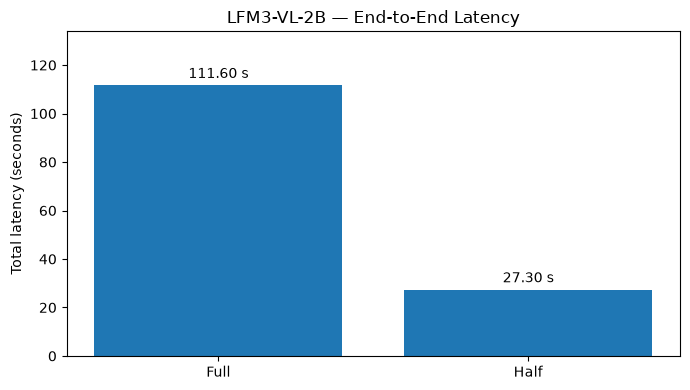

Total speedup: 4.09x


In [15]:

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(runs["variant"], runs["total_s"])

ax.set_ylabel("Total latency (seconds)")
ax.set_title("LFM3-VL-2B — End-to-End Latency")
ax.set_ylim(0, runs["total_s"].max() * 1.2)

ax.bar_label(bars, fmt="%.2f s", padding=3)

plt.tight_layout()
plt.show()

total_speedup = (
    runs.iloc[0]["total_s"] /
    runs.iloc[1]["total_s"]
)

print(f"Total speedup: {total_speedup:.2f}x")


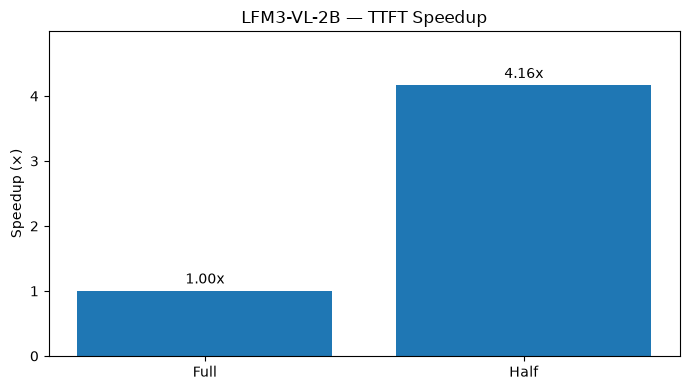

In [16]:

baseline = runs.iloc[0]["ttft_s"]

runs["speedup"] = baseline / runs["ttft_s"]

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(runs["variant"], runs["speedup"])

ax.set_ylabel("Speedup (×)")
ax.set_title("LFM3-VL-2B — TTFT Speedup")
ax.set_ylim(0, runs["speedup"].max() * 1.2)

ax.bar_label(bars, fmt="%.2fx", padding=3)

plt.tight_layout()
plt.show()


  variant  speedup  total_speedup
0    Full    1.000          1.000
1    Half    4.162          4.088


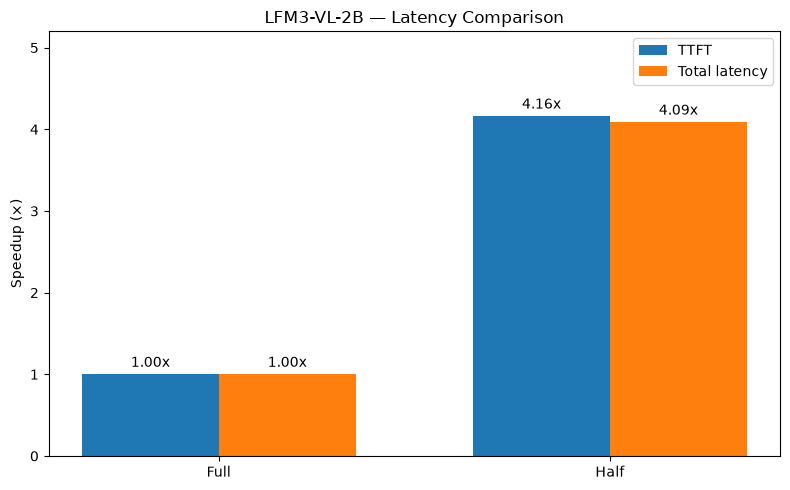

In [17]:

import numpy as np

# Calculate total latency speedup
baseline_total = runs.iloc[0]["total_s"]
runs["total_speedup"] = baseline_total / runs["total_s"]

print(runs[["variant", "speedup", "total_speedup"]].round(3))

# Grouped bar chart
x = np.arange(len(runs))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

bars1 = ax.bar(
    x - width/2, runs["speedup"],
    width, label="TTFT"
)

bars2 = ax.bar(
    x + width/2, runs["total_speedup"],
    width, label="Total latency"
)

ax.set_xticks(x)
ax.set_xticklabels(runs["variant"])
ax.set_ylabel("Speedup (×)")
ax.set_title("LFM3-VL-2B — Latency Comparison")
ax.set_ylim(0, 5.2)
ax.legend()

ax.bar_label(bars1, fmt="%.2fx", padding=3)
ax.bar_label(bars2, fmt="%.2fx", padding=3)

plt.tight_layout()
plt.show()


In [18]:

runs["post_first_token_s"] = (
    runs["total_s"] - runs["ttft_s"]
)

runs["ttft_fraction"] = (
    runs["ttft_s"] / runs["total_s"]
)

print(runs[[
    "variant",
    "post_first_token_s",
    "ttft_fraction"
]].round(4))


  variant  post_first_token_s  ttft_fraction
0    Full                0.67         0.9940
1    Half                0.65         0.9762


In [20]:
!pip install requests

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 687.6 kB/s eta 0:00:00:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 1.5 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.1/135.1 kB 941.2 kB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 257.6/257.6 kB 2.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.6/69.6 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.7/135.7 kB 6.3 MB/s eta 0:00:00


In [23]:

import requests
import pandas as pd
import time
import json
import base64

from PIL import Image
from io import BytesIO
from pathlib import Path

SERVER = "http://127.0.0.1:8180"

response = requests.get(
    f"{SERVER}/v1/models", timeout=10
)
response.raise_for_status()

MODEL = response.json()["data"][0]["id"]
print("Connected to:", MODEL)


Connected to: lfm3-vision


Original resolution: (836, 470)


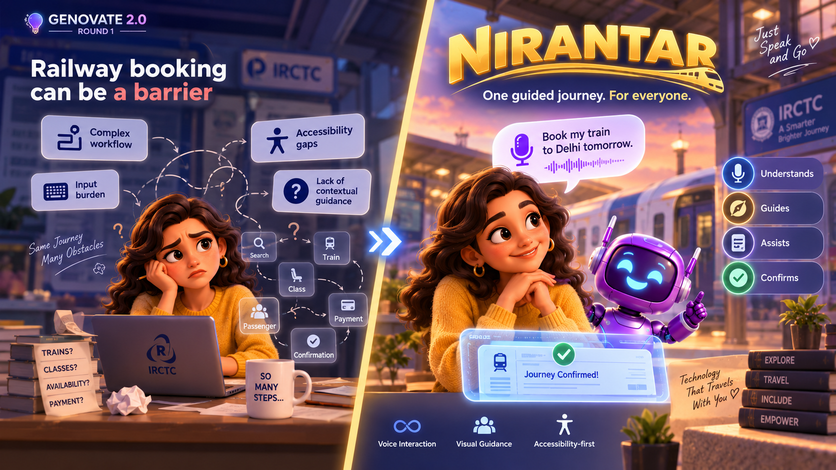

In [25]:
from PIL import Image
from pathlib import Path
from IPython.display import display

# change this path to your real image path
IMAGE_PATH = Path("/home/pratay-karali/Desktop/flowstate/lfm3-prismlab/data/images/imag2_half.png")

image = Image.open(IMAGE_PATH).convert("RGB")

print("Original resolution:", image.size)
display(image)

In [26]:
PROMPT = "Read the main title. Reply with only the title."
EXPECTED = "NIRANTAR"

import time
import json
import base64
from io import BytesIO

def benchmark_vision(scale):
    width = round(image.width * scale)
    height = round(image.height * scale)

    resized = image.resize(
        (width, height),
        Image.Resampling.LANCZOS
    )

    buffer = BytesIO()
    resized.save(buffer, format="PNG")

    encoded = base64.b64encode(
        buffer.getvalue()
    ).decode("ascii")

    payload = {
        "model": MODEL,
        "messages": [{
            "role": "user",
            "content": [
                {"type": "text", "text": PROMPT},
                {
                    "type": "image_url",
                    "image_url": {
                        "url": "data:image/png;base64," + encoded
                    }
                }
            ]
        }],
        "temperature": 0,
        "max_tokens": 32,
        "stream": True
    }

    start = time.perf_counter()
    first_content = None
    tokens = []

    with requests.post(
        f"{SERVER}/v1/chat/completions",
        json=payload,
        stream=True,
        timeout=(15, 300)
    ) as response:
        response.raise_for_status()

        for line in response.iter_lines():
            if not line:
                continue

            line = line.decode("utf-8")

            if not line.startswith("data: "):
                continue

            data = line[6:].strip()
            if data == "[DONE]":
                break

            chunk = json.loads(data)
            choices = chunk.get("choices", [])

            if not choices:
                continue

            piece = choices[0].get(
                "delta", {}
            ).get("content", "")

            if isinstance(piece, str) and piece:
                if first_content is None:
                    first_content = time.perf_counter()
                tokens.append(piece)

    end = time.perf_counter()

    answer = "".join(tokens).strip()
    correct = answer.strip('"\' .').upper() == EXPECTED

    return {
        "scale": scale,
        "resolution": f"{width}x{height}",
        "ttft_s": round(first_content - start, 2) if first_content else None,
        "total_s": round(end - start, 2),
        "answer": answer,
        "correct": correct
    }

In [27]:
result_25 = benchmark_vision(0.25)
print(json.dumps(result_25, indent=2))

{
  "scale": 0.25,
  "resolution": "209x118",
  "ttft_s": null,
  "total_s": 8.01,
  "answer": "",
  "correct": false
}


In [28]:
results = []

for scale in [1.00, 0.50, 0.25]:
    result = benchmark_vision(scale)
    results.append(result)
    print(result)

runs_n2 = pd.DataFrame(results)
runs_n2

{'scale': 1.0, 'resolution': '836x470', 'ttft_s': None, 'total_s': 26.11, 'answer': '', 'correct': False}
{'scale': 0.5, 'resolution': '418x235', 'ttft_s': None, 'total_s': 11.14, 'answer': '', 'correct': False}
{'scale': 0.25, 'resolution': '209x118', 'ttft_s': None, 'total_s': 9.95, 'answer': '', 'correct': False}


,scale,resolution,ttft_s,total_s,answer,correct
0,1.00,836x470,None,26.11,,False
1,0.50,418x235,None,11.14,,False
2,0.25,209x118,None,9.95,,False


In [29]:
from pathlib import Path

Path("results").mkdir(exist_ok=True)
runs_n2.to_csv("results/p2_n2.csv", index=False)

print("Saved to results/p2_n2.csv")

Saved to results/p2_n2.csv


In [30]:

from io import BytesIO
import base64
import requests

buffer = BytesIO()
image.save(buffer, format="PNG")

encoded = base64.b64encode(
    buffer.getvalue()
).decode("ascii")

payload = {
    "model": MODEL,
    "messages": [{
        "role": "user",
        "content": [
            {
                "type": "text",
                "text": "Read the large yellow title. Reply with only its text."
            },
            {
                "type": "image_url",
                "image_url": {
                    "url": "data:image/png;base64," + encoded
                }
            }
        ]
    }],
    "temperature": 0.1,
    "max_tokens": 128,
    "stream": False
}

response = requests.post(
    f"{SERVER}/v1/chat/completions",
    json=payload,
    timeout=(15, 300)
)

response.raise_for_status()
data = response.json()

choice = data["choices"][0]
message = choice["message"]

print("Finish reason:", choice.get("finish_reason"))
print("Message keys:", list(message.keys()))
print("Content:", repr(message.get("content")))
print("Reasoning present:", bool(message.get("reasoning_content")))
print("Usage:", data.get("usage"))


Finish reason: stop
Message keys: ['role', 'content', 'reasoning_content']
Content: 'NIRANTAR'
Reasoning present: True
Usage: {'completion_tokens': 85, 'prompt_tokens': 415, 'total_tokens': 500, 'prompt_tokens_details': {'cached_tokens': 0}}


In [31]:
PROMPT = "Read the large yellow title. Reply with only its text."
EXPECTED = "NIRANTAR"

In [32]:

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import json
import base64

from pathlib import Path
from io import BytesIO
from PIL import Image
from IPython.display import display

# Reuse the working server URL from your previous cell
SERVER = globals().get(
    "SERVER", "http://127.0.0.1:8180"
)

response = requests.get(
    f"{SERVER}/v1/models",
    timeout=10
)
response.raise_for_status()

MODEL = response.json()["data"][0]["id"]

print("Server:", SERVER)
print("Connected model:", MODEL)


Server: http://127.0.0.1:8180
Connected model: lfm3-vision


Original resolution: (836, 470)
Expected answer: NIRANTAR


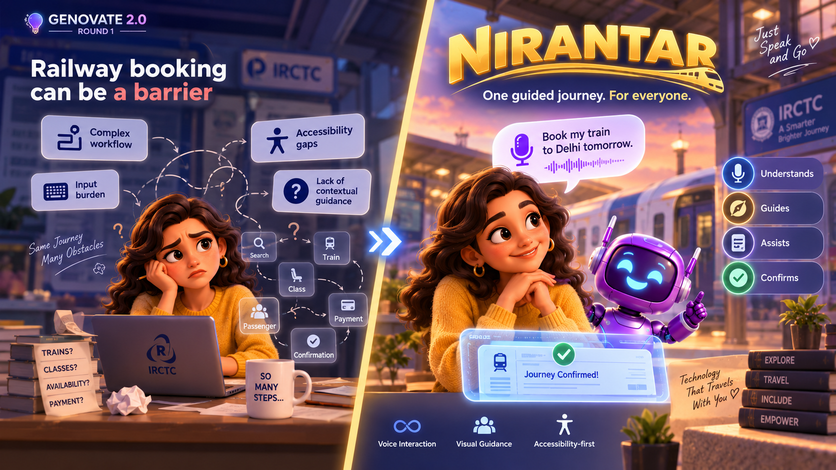

In [33]:

# Reuse our existing NIRANTAR image
if "image" in globals():
    image = image.convert("RGB")
elif "IMAGE_PATH" in globals():
    image = Image.open(IMAGE_PATH).convert("RGB")
else:
    raise RuntimeError(
        "Load your NIRANTAR image into the "
        "'image' variable before continuing."
    )

PROMPT = (
    "Read the large yellow title. "
    "Reply with only its text."
)
EXPECTED = "NIRANTAR"

print("Original resolution:", image.size)
print("Expected answer:", EXPECTED)

display(image)


In [34]:

def benchmark_vision(scale, trial=1):
    width = round(image.width * scale)
    height = round(image.height * scale)

    resized = image.resize(
        (width, height),
        Image.Resampling.LANCZOS
    )

    buffer = BytesIO()
    resized.save(buffer, format="PNG")

    encoded = base64.b64encode(
        buffer.getvalue()
    ).decode("ascii")

    payload = {
        "model": MODEL,
        "messages": [{
            "role": "user",
            "content": [
                {
                    "type": "text",
                    "text": PROMPT
                },
                {
                    "type": "image_url",
                    "image_url": {
                        "url": (
                            "data:image/png;base64,"
                            + encoded
                        )
                    }
                }
            ]
        }],
        "temperature": 0,
        "max_tokens": 192,
        "stream": True
    }

    start = time.perf_counter()

    first_content = None
    first_event = None
    content_parts = []
    reasoning_seen = False
    finish_reason = None

    with requests.post(
        f"{SERVER}/v1/chat/completions",
        json=payload,
        stream=True,
        timeout=(15, 300)
    ) as response:

        response.raise_for_status()

        for raw_line in response.iter_lines():
            if not raw_line:
                continue

            line = raw_line.decode("utf-8")

            if not line.startswith("data:"):
                continue

            data = line[5:].strip()

            if data == "[DONE]":
                break

            chunk = json.loads(data)

            if first_event is None:
                first_event = time.perf_counter()

            choices = chunk.get("choices", [])

            if not choices:
                continue

            choice = choices[0]
            delta = choice.get("delta") or {}

            if choice.get("finish_reason") is not None:
                finish_reason = choice["finish_reason"]

            # Track reasoning separately
            reasoning = delta.get("reasoning_content")

            if reasoning:
                reasoning_seen = True

            # Capture visible generated text
            piece = delta.get("content")

            if isinstance(piece, str) and piece:
                if first_content is None:
                    first_content = time.perf_counter()
                content_parts.append(piece)

    end = time.perf_counter()

    answer = "".join(content_parts).strip()
    valid_output = bool(answer)

    normalized = answer.strip('"\' .').upper()

    correct = (
        normalized == EXPECTED
        if valid_output else None
    )

    return {
        "trial": trial,
        "scale": scale,
        "resolution": f"{width}x{height}",
        "ttft_s": (
            round(first_content - start, 2)
            if first_content is not None else None
        ),
        "first_event_s": (
            round(first_event - start, 2)
            if first_event is not None else None
        ),
        "total_s": round(end - start, 2),
        "answer": answer,
        "valid_output": valid_output,
        "correct": correct,
        "finish_reason": finish_reason,
        "reasoning_seen": reasoning_seen
    }

print("Benchmark function ready!")


Benchmark function ready!


In [35]:

test = benchmark_vision(1.0)

print(json.dumps(test, indent=2))

assert test["valid_output"], (
    "No visible answer captured. "
    "Check finish_reason and reasoning output."
)


{
  "trial": 1,
  "scale": 1.0,
  "resolution": "836x470",
  "ttft_s": 31.84,
  "first_event_s": 21.24,
  "total_s": 32.38,
  "answer": "NIRANTAR",
  "valid_output": true,
  "correct": true,
  "finish_reason": "stop",
  "reasoning_seen": true
}


In [36]:

results = []

for scale in [1.0, 0.5, 0.25]:
    print(f"\nTesting scale {scale}...")

    result = benchmark_vision(scale)
    results.append(result)

    print(
        "Resolution:", result["resolution"],
        "| TTFT:", result["ttft_s"],
        "| Total:", result["total_s"],
        "| Answer:", repr(result["answer"]),
        "| Correct:", result["correct"]
    )

runs_n2 = pd.DataFrame(results)

display(runs_n2[[
    "scale",
    "resolution",
    "ttft_s",
    "total_s",
    "answer",
    "valid_output",
    "correct",
    "finish_reason"
]])



Testing scale 1.0...
Resolution: 836x470 | TTFT: 31.45 | Total: 32.03 | Answer: 'NIRANTAR' | Correct: True

Testing scale 0.5...
Resolution: 418x235 | TTFT: 16.22 | Total: 16.69 | Answer: 'NIRANTAR' | Correct: True

Testing scale 0.25...
Resolution: 209x118 | TTFT: 19.34 | Total: 19.92 | Answer: 'Nirantar' | Correct: True


,scale,resolution,ttft_s,total_s,answer,valid_output,correct,finish_reason
0,1.00,836x470,31.45,32.03,NIRANTAR,True,True,stop
1,0.50,418x235,16.22,16.69,NIRANTAR,True,True,stop
2,0.25,209x118,19.34,19.92,Nirantar,True,True,stop


In [37]:

results = []

for scale in [1.0, 0.5, 0.25]:
    print(f"\nTesting scale {scale}...")

    result = benchmark_vision(scale)
    results.append(result)

    print(
        "Resolution:", result["resolution"],
        "| TTFT:", result["ttft_s"],
        "| Total:", result["total_s"],
        "| Answer:", repr(result["answer"]),
        "| Correct:", result["correct"]
    )

runs_n2 = pd.DataFrame(results)

display(runs_n2[[
    "scale",
    "resolution",
    "ttft_s",
    "total_s",
    "answer",
    "valid_output",
    "correct",
    "finish_reason"
]])



Testing scale 1.0...
Resolution: 836x470 | TTFT: 28.01 | Total: 28.41 | Answer: 'NIRANTAR' | Correct: True

Testing scale 0.5...
Resolution: 418x235 | TTFT: 15.33 | Total: 15.8 | Answer: 'NIRANTAR' | Correct: True

Testing scale 0.25...
Resolution: 209x118 | TTFT: 13.12 | Total: 13.57 | Answer: 'Nirantar' | Correct: True


,scale,resolution,ttft_s,total_s,answer,valid_output,correct,finish_reason
0,1.00,836x470,28.01,28.41,NIRANTAR,True,True,stop
1,0.50,418x235,15.33,15.80,NIRANTAR,True,True,stop
2,0.25,209x118,13.12,13.57,Nirantar,True,True,stop


In [38]:

OUT_DIR = Path("results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

csv_path = OUT_DIR / "p2_n2_resolution_ablation.csv"
json_path = OUT_DIR / "p2_n2_resolution_ablation.json"

runs_n2.to_csv(csv_path, index=False)

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)

print("Saved CSV:", csv_path.resolve())
print("Saved JSON:", json_path.resolve())


Saved CSV: /home/pratay-karali/Desktop/flowstate/lfm3-prismlab/notebooks/results/p2_n2_resolution_ablation.csv
Saved JSON: /home/pratay-karali/Desktop/flowstate/lfm3-prismlab/notebooks/results/p2_n2_resolution_ablation.json


In [39]:

history = pd.DataFrame([
    [1, 1.00, "836x470", 28.01, 28.41, True],
    [1, 0.50, "418x235", 15.33, 15.80, True],
    [1, 0.25, "209x118", 13.12, 13.57, True],
    [2, 1.00, "836x470", 31.45, 32.03, True],
    [2, 0.50, "418x235", 16.22, 16.69, True],
    [2, 0.25, "209x118", 19.34, 19.92, True],
], columns=[
    "trial", "scale", "resolution",
    "ttft_s", "total_s", "correct"
])

summary = history.groupby("resolution").agg(
    trials=("trial", "count"),
    mean_ttft=("ttft_s", "mean"),
    mean_total=("total_s", "mean"),
    success_rate=("correct", "mean")
)

display(summary.round(3))

Path("results").mkdir(exist_ok=True)
history.to_csv(
    "results/p2_n2_two_trials.csv",
    index=False
)


,trials,mean_ttft,mean_total,success_rate
resolution,,,,
209x118,2,16.230,16.745,1.0
418x235,2,15.775,16.245,1.0
836x470,2,29.730,30.220,1.0


In [40]:

import re

expected_labels = [
    "Complex workflow",
    "Input burden",
    "Accessibility gaps",
    "Lack of contextual guidance"
]

def normalize_text(text):
    return re.sub(
        r"\s+", " ",
        re.sub(r"[^a-z0-9]+", " ", text.lower())
    ).strip()

original_prompt = PROMPT

try:
    PROMPT = (
        "Read the text in the four small problem "
        "boxes on the LEFT side of this infographic. "
        "Return only the four phrases, one per line. "
        "Do not add explanations."
    )

    label_results = []

    for scale in [1.0, 0.5, 0.25]:
        result = benchmark_vision(scale)

        # The original correctness test checks NIRANTAR.
        # It is not applicable to this task.
        result.pop("correct", None)

        normalized_answer = normalize_text(
            result["answer"]
        )

        found = [
            label for label in expected_labels
            if normalize_text(label) in normalized_answer
        ]

        result["labels_found"] = found
        result["labels_correct"] = len(found)
        result["label_recall"] = len(found) / 4

        label_results.append(result)

        print(
            f"{result['resolution']}: "
            f"{len(found)}/4 labels | "
            f"{result['total_s']}s"
        )
        print("Answer:", repr(result["answer"]))

finally:
    PROMPT = original_prompt

labels_df = pd.DataFrame(label_results)

display(labels_df[[
    "resolution", "ttft_s", "total_s",
    "labels_correct", "label_recall",
    "valid_output"
]])


836x470: 0/4 labels | 32.8s
Answer: ''
418x235: 0/4 labels | 17.58s
Answer: ''
209x118: 0/4 labels | 19.72s
Answer: ''


,resolution,ttft_s,total_s,labels_correct,label_recall,valid_output
0,836x470,None,32.80,0,0.0,False
1,418x235,None,17.58,0,0.0,False
2,209x118,None,19.72,0,0.0,False


In [ ]:
 
fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    labels_df["resolution"],
    labels_df["label_recall"] * 100
)

ax.set_title("LFM3-VL-2B — Four-label OCR Recall")
ax.set_ylabel("Exact phrase recall (%)")
ax.set_xlabel("Image resolution")
ax.set_ylim(0, 110)

ax.bar_label(bars, fmt="%.0f%%", padding=3)

plt.tight_layout()
plt.show()

labels_df.to_csv(
    "results/p2_n3_multi_label_ocr.csv",
    index=False
)
